In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('creditcard1.csv')
print(f"Dimensi dataset awal: {df.shape}")

Dimensi dataset awal: (284807, 31)


In [3]:
print("MISSING VALUE & DATA DUPLIKAT")
# 1. Cek Missing Value
missing_data = df.isnull().sum()
print("Jumlah Missing Value per kolom:")
print(missing_data[missing_data > 0])

# 2. Cek Data Duplikat
duplicates = df.duplicated().sum()
print(f"\nJumlah Baris Duplikat: {duplicates}")

# # Menghapus duplikat, karena duplikat bisa membuat model bias
# if duplicates > 0:
#     df = df.drop_duplicates()
#     print(f"Dimensi dataset setelah menghapus duplikat: {df.shape}")

MISSING VALUE & DATA DUPLIKAT
Jumlah Missing Value per kolom:
Series([], dtype: int64)

Jumlah Baris Duplikat: 1081



--- OUTLIER ---


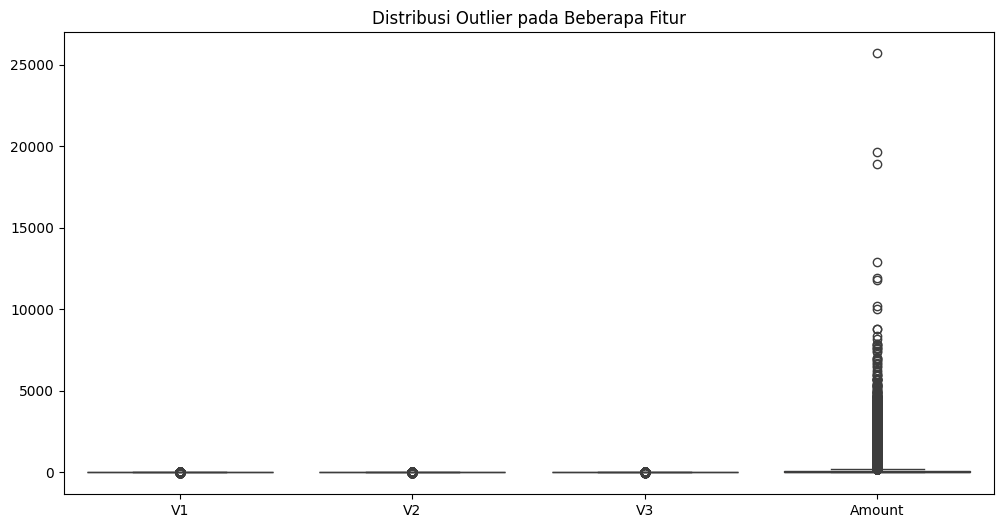

In [4]:
print("\n--- OUTLIER ---")
# saya ambil 4 kolom pertama saja agar visualisasinya tidak terlalu padat
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[['V1', 'V2', 'V3', 'Amount']])
plt.title("Distribusi Outlier pada Beberapa Fitur")
plt.show()

In [5]:
print("\nCONSTANT FEATURE")
constant_features = [col for col in df.columns if df[col].nunique() == 1]

if len(constant_features) > 0:
    print(f"Ditemukan {len(constant_features)} fitur konstan: {constant_features}")
    # df = df.drop(columns=constant_features)
else:
    print("Tidak ditemukan fitur konstan. Semua kolom memiliki variasi nilai.")


CONSTANT FEATURE
Tidak ditemukan fitur konstan. Semua kolom memiliki variasi nilai.


In [6]:
print("\nFEATURE RANGE (SCALING)")
# Menampilkan nilai Minimum, Maksimum, dan Rata-rata
feature_range = df.describe().loc[['min', 'max', 'mean']]
print(feature_range[['V1', 'V2', 'Amount', 'Time']])

print("\nKesimpulan Skala:")
print("Perhatikan perbedaan mencolok antara nilai maks 'Amount' dengan kolom V lainnya.")
print("Ini membuktikan bahwa proses Scaling (Normalisasi) memang wajib dilakukan.")


FEATURE RANGE (SCALING)
                V1            V2        Amount           Time
min  -5.640751e+01 -7.271573e+01      0.000000       0.000000
max   2.454930e+00  2.205773e+01  25691.160000  172792.000000
mean  1.168375e-15  3.416908e-16     88.349619   94813.859575

Kesimpulan Skala:
Perhatikan perbedaan mencolok antara nilai maks 'Amount' dengan kolom V lainnya.
Ini membuktikan bahwa proses Scaling (Normalisasi) memang wajib dilakukan.



CLASS IMBALANCE
Transaksi Sah (0)     : 284315
Transaksi Penipuan (1): 492
Rasio Penipuan        : 0.173%


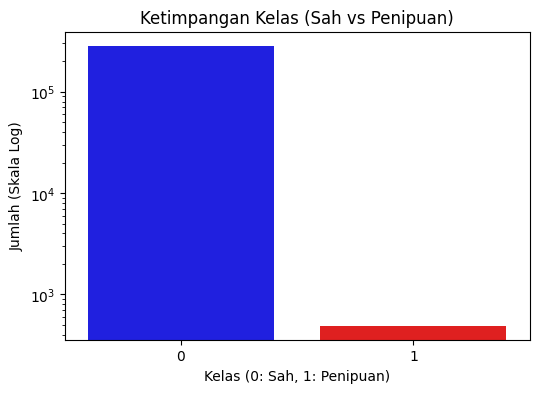

In [7]:
print("\nCLASS IMBALANCE")
class_counts = df['Class'].value_counts()
fraud_ratio = (class_counts[1] / len(df)) * 100

print(f"Transaksi Sah (0)     : {class_counts[0]}")
print(f"Transaksi Penipuan (1): {class_counts[1]}")
print(f"Rasio Penipuan        : {fraud_ratio:.3f}%")

# Visualisasi Imbalance
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df, hue='Class', palette=['blue', 'red'], legend=False)
plt.title('Ketimpangan Kelas (Sah vs Penipuan)')
plt.yscale('log') 
plt.xlabel('Kelas (0: Sah, 1: Penipuan)')
plt.ylabel('Jumlah (Skala Log)')
plt.show()

In [8]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE

if df.isnull().sum().max() > 0:
    df = df.fillna(df.mean())

X = df.drop(['Class', 'Time'], axis=1).values
y = df['Class'].values

In [9]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
def build_ae_rbce_model(input_dim):
    input_layer = Input(shape=(input_dim,))
    
    encoded = Dense(512, activation='relu', kernel_regularizer=l2(0.01))(input_layer)
    latent_space = Dense(256, activation='relu', kernel_regularizer=l2(0.01))(encoded)
    
    decoded = Dense(512, activation='relu', kernel_regularizer=l2(0.01))(latent_space)
    output_layer = Dense(input_dim, activation='linear')(decoded) 
    
    ae = Model(inputs=input_layer, outputs=output_layer)
    optimizer = Adam(learning_rate=0.0001)
    ae.compile(optimizer=optimizer, loss='binary_crossentropy')
    
    return ae

In [18]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_curve, accuracy_score, recall_score, roc_auc_score, confusion_matrix
from imblearn.over_sampling import SMOTE
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
smote = SMOTE(random_state=42)

for train_index, test_index in skf.split(X_scaled, y):
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
    
    ae_model = build_ae_rbce_model(X_train.shape[1])

    early_stop = EarlyStopping(
        monitor='val_loss',       
        patience=5,                
        restore_best_weights=True  
    )
    
    print("--- MULAI TRAINING MODEL ---")
    ae_model.fit(
        X_train_res, X_train_res, 
        epochs=50, 
        batch_size=64, 
        validation_split=0.1,      
        callbacks=[early_stop],    
        verbose=1
    )
    
    X_pred = ae_model.predict(X_test)
    mse = np.mean(np.power(X_test - X_pred, 2), axis=1)
    
    threshold = 0.70
    
    y_pred = (mse > threshold).astype(int)
    
    print("\n=====================================================")
    print("  HASIL EVALUASI MODEL (SMOTE + DYNAMIC THRESHOLD) ")
    print("=====================================================")
    print(f"Accuracy       : {accuracy_score(y_test, y_pred) * 100:.3f}%")
    print(f"Detection Rate : {recall_score(y_test, y_pred) * 100:.3f}%")
    print(f"AUC            : {roc_auc_score(y_test, mse) * 100:.3f}%")
    
    # Detail Kebingungan Model (Confusion Matrix)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print("\n--- RINCIAN CONFUSION MATRIX ---")
    print(f"Transaksi Sah yang benar ditebak Sah (TN)  : {tn}")
    print(f"Transaksi Sah yang SALAH DIBLOKIR (FP)     : {fp}")
    print(f"Transaksi Penipuan yang LOLOS (FN)         : {fn}")
    print(f"Transaksi Penipuan yang TERTANGKAP (TP)    : {tp}")
    
    break

--- MULAI TRAINING MODEL ---
Epoch 1/50
6398/6398 ━━━━━━━━━━━━━━━━━━━━ 31s 4ms/step - loss: -10.3136 - val_loss: -28.3148
Epoch 2/50
3193/6398 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - loss: -11.5904

KeyboardInterrupt: 

In [15]:
from sklearn.metrics import classification_report

print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=['Sah (0)', 'Penipuan (1)']))


--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

     Sah (0)       1.00      0.97      0.99     56863
Penipuan (1)       0.05      0.82      0.09        99

    accuracy                           0.97     56962
   macro avg       0.53      0.90      0.54     56962
weighted avg       1.00      0.97      0.98     56962



--- RINCIAN CONFUSION MATRIX ---
True Negative (TN)  : 55337 -> Transaksi SAH yang benar ditebak SAH (Aman)
False Positive (FP) : 1526 -> Transaksi SAH yang DIBLOKIR (Alarm Palsu / Bencana)
False Negative (FN) : 18 -> Transaksi PENIPUAN yang LOLOS (Kebobolan)
True Positive (TP)  : 81 -> Transaksi PENIPUAN yang TERTANGKAP (Sukses)
------------------------------
Total Nasabah Sah yang Dirugikan (FP) : 1526 transaksi


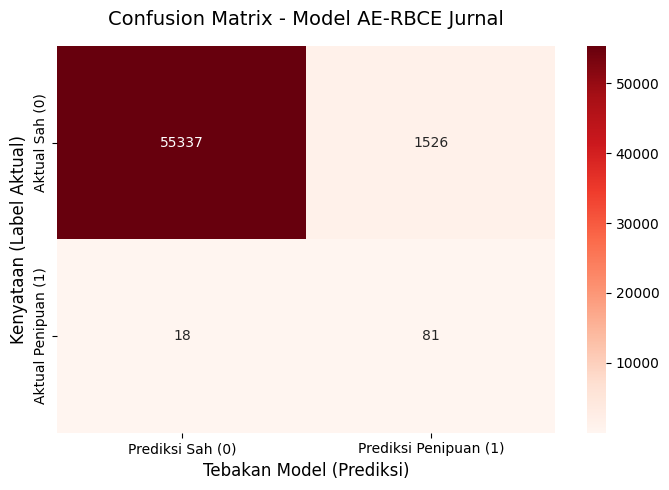

In [16]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan y_test dan y_pred sudah ada di memori dari eksekusi sebelumnya
cm = confusion_matrix(y_test, y_pred)

# 1. TAMPILAN TEKS (Mendetail)
print("--- RINCIAN CONFUSION MATRIX ---")
print(f"True Negative (TN)  : {cm[0][0]} -> Transaksi SAH yang benar ditebak SAH (Aman)")
print(f"False Positive (FP) : {cm[0][1]} -> Transaksi SAH yang DIBLOKIR (Alarm Palsu / Bencana)")
print(f"False Negative (FN) : {cm[1][0]} -> Transaksi PENIPUAN yang LOLOS (Kebobolan)")
print(f"True Positive (TP)  : {cm[1][1]} -> Transaksi PENIPUAN yang TERTANGKAP (Sukses)")

print("-" * 30)
print(f"Total Nasabah Sah yang Dirugikan (FP) : {cm[0][1]} transaksi")

# 2. TAMPILAN GRAFIK (Untuk Laporan/Jurnal)
plt.figure(figsize=(7, 5))
# fmt='d' agar angkanya ditampilkan utuh, tidak pakai format desimal ilmiah
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', 
            xticklabels=['Prediksi Sah (0)', 'Prediksi Penipuan (1)'],
            yticklabels=['Aktual Sah (0)', 'Aktual Penipuan (1)'])

plt.title('Confusion Matrix - Model AE-RBCE Jurnal', fontsize=14, pad=15)
plt.ylabel('Kenyataan (Label Aktual)', fontsize=12)
plt.xlabel('Tebakan Model (Prediksi)', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import StratifiedKFold
from imblearn.over_sampling import SMOTE
import pandas as pd

# Inisialisasi Stratified K-Fold (5 fold) dan SMOTE
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
smote = SMOTE(random_state=42)

fold_no = 1
for train_index, test_index in skf.split(X_scaled, y):
    # 1. Membelah data berdasarkan index K-Fold
    # Gunakan .iloc jika X_scaled dan y berupa Pandas DataFrame/Series
    # Jika berupa numpy array, hapus .iloc menjadi X_scaled[train_index]
    X_train, X_test = X_scaled[train_index], X_scaled[test_index]
    y_train, y_test = y[train_index], y[test_index]
    
    print(f"--- INFO PEMBAGIAN DATA FOLD KE-{fold_no} ---")
    print(f"1. Data Uji (Test Set) murni       : {len(X_test)} baris (20%)")
    print(f"2. Data Latih (Train Set) awal     : {len(X_train)} baris (80%)")
    
    # Cek rincian kelas di Data Latih sebelum SMOTE
    print(f"   -> Jumlah Transaksi Sah         : {sum(y_train == 0)}")
    print(f"   -> Jumlah Transaksi Penipuan    : {sum(y_train == 1)}")
    
    # 2. Terapkan SMOTE khusus pada Data Latih
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
    
    print(f"\n3. Data Latih SETELAH di-SMOTE     : {len(X_train_resampled)} baris")
    print(f"   -> Jumlah Transaksi Sah         : {sum(y_train_resampled == 0)}")
    print(f"   -> Jumlah Transaksi Penipuan    : {sum(y_train_resampled == 1)}\n")
    
    break # Kita hentikan (break) agar hanya mencetak fold pertama saja untuk laporan

In [ ]:
# Pastikan y_test dan y_pred sudah dieksekusi sebelumnya
from sklearn.metrics import confusion_matrix

# Ekstrak nilai dari Confusion Matrix
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

# Hitung total masing-masing kelas aktual
total_sah = tn + fp
total_fraud = fn + tp
total_transaksi = total_sah + total_fraud

print("=====================================================")
print("  LAPORAN RINCIAN KINERJA MODEL (BERDASARKAN MATRIKS) ")
print("=====================================================\n")

print(f"Total Data Uji (Test Set) : {total_transaksi} transaksi\n")

print("--- EVALUASI KELAS SAH (0) ---")
print(f"Total Transaksi Sah Aktual : {total_sah} transaksi")
print(f"Berhasil Ditebak Sah (TN)  : {tn} transaksi (Aman)")
print(f"SALAH BLOKIR (FP)          : {fp} transaksi (Ini adalah Alarm Palsu / Nasabah Dirugikan!)")
print(f"   -> Model salah memblokir {fp/total_sah*100:.2f}% dari seluruh transaksi sah.\n")

print("--- EVALUASI KELAS PENIPUAN / FRAUD (1) ---")
print(f"Total Transaksi Fraud Aktual: {total_fraud} transaksi")
print(f"Berhasil Ditangkap (TP)    : {tp} transaksi (Penipu tertangkap)")
print(f"Gagal Ditangkap (FN)       : {fn} transaksi (Penipu lolos)")
print(f"   -> Model berhasil menangkap {tp/total_fraud*100:.2f}% dari seluruh penipuan (Ini adalah Detection Rate-nya).")
print("=====================================================")